In [60]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from LearningAlgorithms import ClassificationAlgorithms
import seaborn as sns
import itertools
from sklearn.metrics import accuracy_score, confusion_matrix

In [61]:

# Plot settings
plt.style.use("fivethirtyeight")
plt.rcParams["figure.figsize"] = (20, 5)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["lines.linewidth"] = 2

In [62]:
df=pd.read_pickle("../data/interim/03_data_features.pkl")

In [63]:
df_train=df.drop(["participant","category","set"],axis=1)

In [64]:
df_train

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,label,duration,pca_1,pca_2,...,gyr_r_pse,gyr_r_freq_0.0_Hz_ws_14,gyr_r_freq_0.357_Hz_ws_14,gyr_r_freq_0.714_Hz_ws_14,gyr_r_freq_1.071_Hz_ws_14,gyr_r_freq_1.429_Hz_ws_14,gyr_r_freq_1.786_Hz_ws_14,gyr_r_freq_2.143_Hz_ws_14,gyr_r_freq_2.5_Hz_ws_14,cluster
epoch (ms),,,,,,,,,,,,,,,,,,,,,
2019-01-11 15:08:08.000,-0.164924,0.865523,-0.178538,-20.541984,-8.226941,21.708715,bench,16.0,-0.302452,-0.174384,...,0.348493,182.101298,-22.460551,8.212900,12.208705,-18.398900,2.046792,-34.381447,-14.045145,0
2019-01-11 15:08:08.400,-0.037702,0.893562,-0.054992,-8.757968,-3.388710,5.934664,bench,16.0,-0.297706,-0.078522,...,0.366945,218.077345,1.196483,-59.149485,-31.789010,-5.715577,12.827112,1.699779,-0.802390,0
2019-01-11 15:08:08.800,-0.050594,0.971761,-0.036645,6.755364,-0.667937,-3.858589,bench,16.0,-0.324916,-0.067499,...,0.250244,224.788131,-5.519015,-25.951304,9.344700,1.411426,-39.945304,13.773509,-6.842649,0
2019-01-11 15:08:09.200,-0.054443,0.995092,-0.034129,-3.135521,-4.056549,5.582744,bench,16.0,-0.333726,-0.065737,...,0.477223,208.077866,-29.385794,50.648931,11.469258,5.707674,35.408932,18.023310,0.586241,0
2019-01-11 15:08:09.600,-0.039912,0.883784,-0.060126,15.707099,5.334875,-11.553838,bench,16.0,-0.293580,-0.082578,...,0.432201,191.164632,-28.076080,34.138705,0.052550,11.161164,9.485386,-22.408690,-29.121987,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:26.200,0.058850,-0.909458,0.108233,-29.215392,5.558830,13.450505,row,19.0,0.341528,-0.027145,...,0.218648,340.057969,11.001737,-9.070391,35.790142,-44.934231,-19.424527,-16.025378,-21.283505,4
2019-01-20 17:33:26.600,-0.018615,-1.191105,-0.097478,-10.724922,0.437615,7.609956,row,19.0,0.428434,-0.172445,...,0.181643,340.254610,8.561735,-1.119536,-19.978604,37.057462,36.872676,20.891222,8.593489,1
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,row,19.0,0.364382,-0.160191,...,0.123320,300.550062,-30.374874,-0.553401,5.009928,-16.507914,-22.401157,-1.092554,-11.438781,1


In [65]:
x=df_train.drop("label",axis=1)
y=df_train["label"]

In [66]:
x


,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,duration,pca_1,pca_2,pca_3,...,gyr_r_pse,gyr_r_freq_0.0_Hz_ws_14,gyr_r_freq_0.357_Hz_ws_14,gyr_r_freq_0.714_Hz_ws_14,gyr_r_freq_1.071_Hz_ws_14,gyr_r_freq_1.429_Hz_ws_14,gyr_r_freq_1.786_Hz_ws_14,gyr_r_freq_2.143_Hz_ws_14,gyr_r_freq_2.5_Hz_ws_14,cluster
epoch (ms),,,,,,,,,,,,,,,,,,,,,
2019-01-11 15:08:08.000,-0.164924,0.865523,-0.178538,-20.541984,-8.226941,21.708715,16.0,-0.302452,-0.174384,-0.022459,...,0.348493,182.101298,-22.460551,8.212900,12.208705,-18.398900,2.046792,-34.381447,-14.045145,0
2019-01-11 15:08:08.400,-0.037702,0.893562,-0.054992,-8.757968,-3.388710,5.934664,16.0,-0.297706,-0.078522,0.027817,...,0.366945,218.077345,1.196483,-59.149485,-31.789010,-5.715577,12.827112,1.699779,-0.802390,0
2019-01-11 15:08:08.800,-0.050594,0.971761,-0.036645,6.755364,-0.667937,-3.858589,16.0,-0.324916,-0.067499,0.045315,...,0.250244,224.788131,-5.519015,-25.951304,9.344700,1.411426,-39.945304,13.773509,-6.842649,0
2019-01-11 15:08:09.200,-0.054443,0.995092,-0.034129,-3.135521,-4.056549,5.582744,16.0,-0.333726,-0.065737,0.028790,...,0.477223,208.077866,-29.385794,50.648931,11.469258,5.707674,35.408932,18.023310,0.586241,0
2019-01-11 15:08:09.600,-0.039912,0.883784,-0.060126,15.707099,5.334875,-11.553838,16.0,-0.293580,-0.082578,0.064681,...,0.432201,191.164632,-28.076080,34.138705,0.052550,11.161164,9.485386,-22.408690,-29.121987,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:26.200,0.058850,-0.909458,0.108233,-29.215392,5.558830,13.450505,19.0,0.341528,-0.027145,-0.085179,...,0.218648,340.057969,11.001737,-9.070391,35.790142,-44.934231,-19.424527,-16.025378,-21.283505,4
2019-01-20 17:33:26.600,-0.018615,-1.191105,-0.097478,-10.724922,0.437615,7.609956,19.0,0.428434,-0.172445,-0.062047,...,0.181643,340.254610,8.561735,-1.119536,-19.978604,37.057462,36.872676,20.891222,8.593489,1
2019-01-20 17:33:27.000,-0.048043,-1.010877,-0.077600,7.204016,-5.207856,-0.681873,19.0,0.364382,-0.160191,-0.044117,...,0.123320,300.550062,-30.374874,-0.553401,5.009928,-16.507914,-22.401157,-1.092554,-11.438781,1


In [67]:
y

epoch (ms)
2019-01-11 15:08:08.000    bench
2019-01-11 15:08:08.400    bench
2019-01-11 15:08:08.800    bench
2019-01-11 15:08:09.200    bench
2019-01-11 15:08:09.600    bench
                           ...  
2019-01-20 17:33:26.200      row
2019-01-20 17:33:26.600      row
2019-01-20 17:33:27.000      row
2019-01-20 17:33:27.400      row
2019-01-20 17:33:27.800      row
Name: label, Length: 3868, dtype: object

In [68]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42,stratify=y)

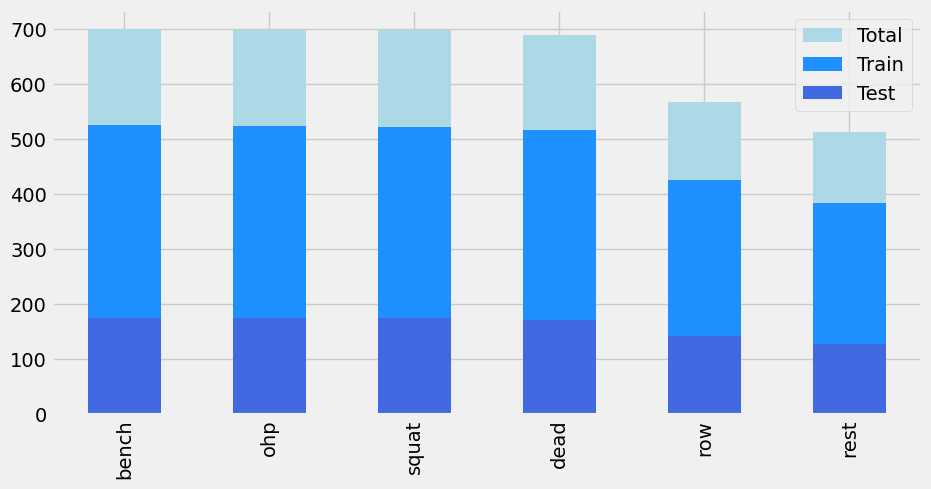

In [69]:
fig, ax = plt.subplots(figsize=(10, 5))
df_train["label"].value_counts().plot(
    kind="bar", ax=ax, color="lightblue", label="Total"
)
y_train.value_counts().plot(kind="bar", ax=ax, color="dodgerblue", label="Train")
y_test.value_counts().plot(kind="bar", ax=ax, color="royalblue", label="Test")
plt.legend()
plt.show()

In [70]:
#split features subsets

In [71]:
basic_features = ["acc_x", "acc_y", "acc_z", "gyr_x", "gyr_y", "gyr_z"]
square_features = ["acc_r", "gyr_r"]
pca_features = ["pca_1", "pca_2", "pca_3"]
time_features = [f for f in df_train.columns if "_temp_" in f]
frequency_features = [f for f in df_train.columns if ("_freq" in f) or ("pse" in f)]
cluster_features = ["cluster"]

In [72]:
print("Basic features:", len(basic_features))
print("Square features:", len(square_features))
print("PCA features:", len(pca_features))
print("Time features:", len(time_features))
print("Frequency features:", len(frequency_features))
print("Cluster features:", len(cluster_features))

Basic features: 6
Square features: 2
PCA features: 3
Time features: 16
Frequency features: 88
Cluster features: 1


In [73]:
feature_set_1 = list(set(basic_features))
feature_set_2 = list(set(basic_features + square_features+ pca_features))
feature_set_3 = list(set(basic_features + time_features))
feature_set_4 = list(set(cluster_features + frequency_features+feature_set_3))

In [74]:
learner=ClassificationAlgorithms()
max_features=10
selected_features,ordered_features,ordered_scores=learner.forward_selection(max_features,x_train,y_train)

0
1
2
3
4
5
6
7
8
9


In [75]:
selected_features

['pca_1',
 'duration',
 'acc_x_freq_0.0_Hz_ws_14',
 'acc_z_freq_0.0_Hz_ws_14',
 'acc_y_temp_mean_ws_5',
 'gyr_r_temp_mean_ws_5',
 'acc_y_freq_1.071_Hz_ws_14',
 'acc_x',
 'gyr_r',
 'gyr_y_freq_1.786_Hz_ws_14']

In [76]:
ordered_features

['pca_1',
 'duration',
 'acc_x_freq_0.0_Hz_ws_14',
 'acc_z_freq_0.0_Hz_ws_14',
 'acc_y_temp_mean_ws_5',
 'gyr_r_temp_mean_ws_5',
 'acc_y_freq_1.071_Hz_ws_14',
 'acc_x',
 'gyr_r',
 'gyr_y_freq_1.786_Hz_ws_14']

In [77]:
ordered_scores

[0.8827990348155809,
 0.9769045156842469,
 0.9975870389520854,
 0.9989658738366081,
 0.9993105825577387,
 0.9996552912788693,
 1.0,
 1.0,
 1.0,
 1.0]

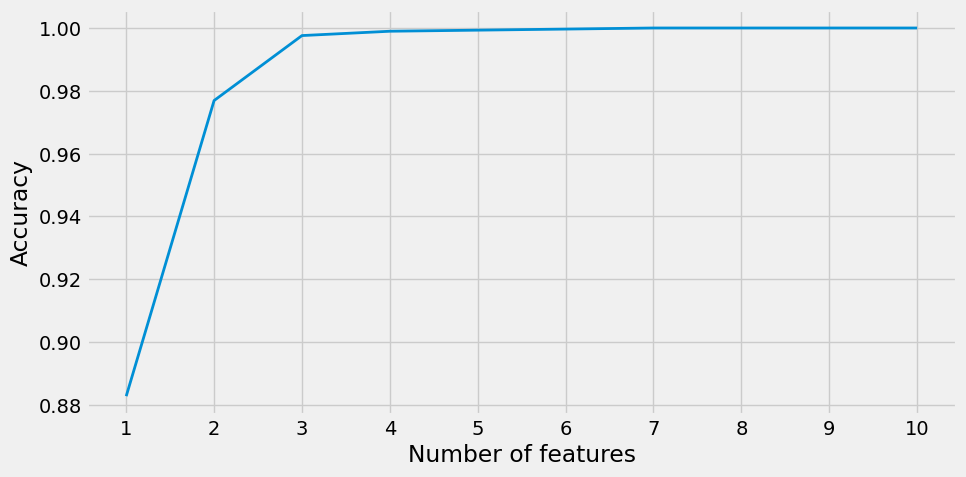

In [78]:
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, max_features + 1, 1), ordered_scores)
plt.xlabel("Number of features")
plt.ylabel("Accuracy")
plt.xticks(np.arange(1, max_features + 1, 1))
plt.show()

In [82]:
selected_features=[
 'pca_1',
 'duration',
 'acc_x_freq_0.0_Hz_ws_14',
 'acc_z_freq_0.0_Hz_ws_14',
 'acc_y_temp_mean_ws_5',
 'gyr_r_temp_mean_ws_5',
 'acc_y_freq_1.071_Hz_ws_14',
 'acc_x',
 'gyr_r',
 'gyr_y_freq_1.786_Hz_ws_14'
]

In [83]:
#grid search for hyperparameter tuning and model selection

In [88]:
possible_features_sets = [
    feature_set_1,
    feature_set_2,      
    feature_set_3,
    feature_set_4,
    selected_features
]
feature_names = [
    "feature_set_1",
    "feature_set_2",
    "feature_set_3",
    "feature_set_4",
    "selected_features"
]

In [91]:
iterations=1
score_df=pd.DataFrame()

for i, f in zip(range(len(possible_features_sets)), feature_names):
    print("Feature set:", i)
    selected_train_x = x_train[possible_features_sets[i]]
    selected_test_x = x_test[possible_features_sets[i]]

    # First run non deterministic classifiers to average their score.
    performance_test_nn = 0
    performance_test_rf = 0

    for it in range(0, iterations):
        print("\tTraining neural network,", it)
        (
            class_train_y,
            class_test_y,
            class_train_prob_y,
            class_test_prob_y,
        ) = learner.feedforward_neural_network(
            selected_train_x,
            y_train,
            selected_test_x,
            gridsearch=False,
        )
        performance_test_nn += accuracy_score(y_test, class_test_y)

        print("\tTraining random forest,", it)
        (
            class_train_y,
            class_test_y,
            class_train_prob_y,
            class_test_prob_y,
        ) = learner.random_forest(
            selected_train_x, y_train, selected_test_x, gridsearch=True
        )
        performance_test_rf += accuracy_score(y_test, class_test_y)

    performance_test_nn = performance_test_nn / iterations
    performance_test_rf = performance_test_rf / iterations

    # And we run our deterministic classifiers:
    print("\tTraining KNN")
    (
        class_train_y,
        class_test_y,
        class_train_prob_y,
        class_test_prob_y,
    ) = learner.k_nearest_neighbor(
        selected_train_x, y_train, selected_test_x, gridsearch=True
    )
    performance_test_knn = accuracy_score(y_test, class_test_y)

    print("\tTraining decision tree")
    (
        class_train_y,
        class_test_y,
        class_train_prob_y,
        class_test_prob_y,
    ) = learner.decision_tree(
        selected_train_x, y_train, selected_test_x, gridsearch=True
    )
    performance_test_dt = accuracy_score(y_test, class_test_y)

    print("\tTraining naive bayes")
    (
        class_train_y,
        class_test_y,
        class_train_prob_y,
        class_test_prob_y,
    ) = learner.naive_bayes(selected_train_x, y_train, selected_test_x)

    performance_test_nb = accuracy_score(y_test, class_test_y)

    # Save results to dataframe
    models = ["NN", "RF", "KNN", "DT", "NB"]
    new_scores = pd.DataFrame(
        {
            "model": models,
            "feature_set": f,
            "accuracy": [
                performance_test_nn,
                performance_test_rf,
                performance_test_knn,
                performance_test_dt,
                performance_test_nb,
            ],
        }
    )
    score_df = pd.concat([score_df, new_scores])


Feature set: 0
	Training neural network, 0
	Training random forest, 0
	Training KNN
	Training decision tree
	Training naive bayes
Feature set: 1
	Training neural network, 0
	Training random forest, 0
	Training KNN
	Training decision tree
	Training naive bayes
Feature set: 2
	Training neural network, 0
	Training random forest, 0
	Training KNN


c:\Users\sarbj\anaconda3\envs\tracking-barbell-exercises\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\sarbj\anaconda3\envs\tracking-barbell-exercises\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\sarbj\anaconda3\envs\tracking-barbell-exercises\lib\subprocess.py", line 493, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\sarbj\anaconda3\envs\tracking-barbell-exercises\lib\subprocess.py", line 858, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\sarbj\anaconda3\envs\tracking-barbell-exercise

	Training decision tree
	Training naive bayes
Feature set: 3
	Training neural network, 0
	Training random forest, 0
	Training KNN
	Training decision tree
	Training naive bayes
Feature set: 4
	Training neural network, 0
	Training random forest, 0
	Training KNN
	Training decision tree
	Training naive bayes


In [92]:
score_df

,model,feature_set,accuracy
0,NN,feature_set_1,0.942089
1,RF,feature_set_1,0.966908
2,KNN,feature_set_1,0.812823
3,DT,feature_set_1,0.932782
4,NB,feature_set_1,0.876939
0,NN,feature_set_2,0.943123
1,RF,feature_set_2,0.958635
2,KNN,feature_set_2,0.798345
3,DT,feature_set_2,0.940021
4,NB,feature_set_2,0.888314


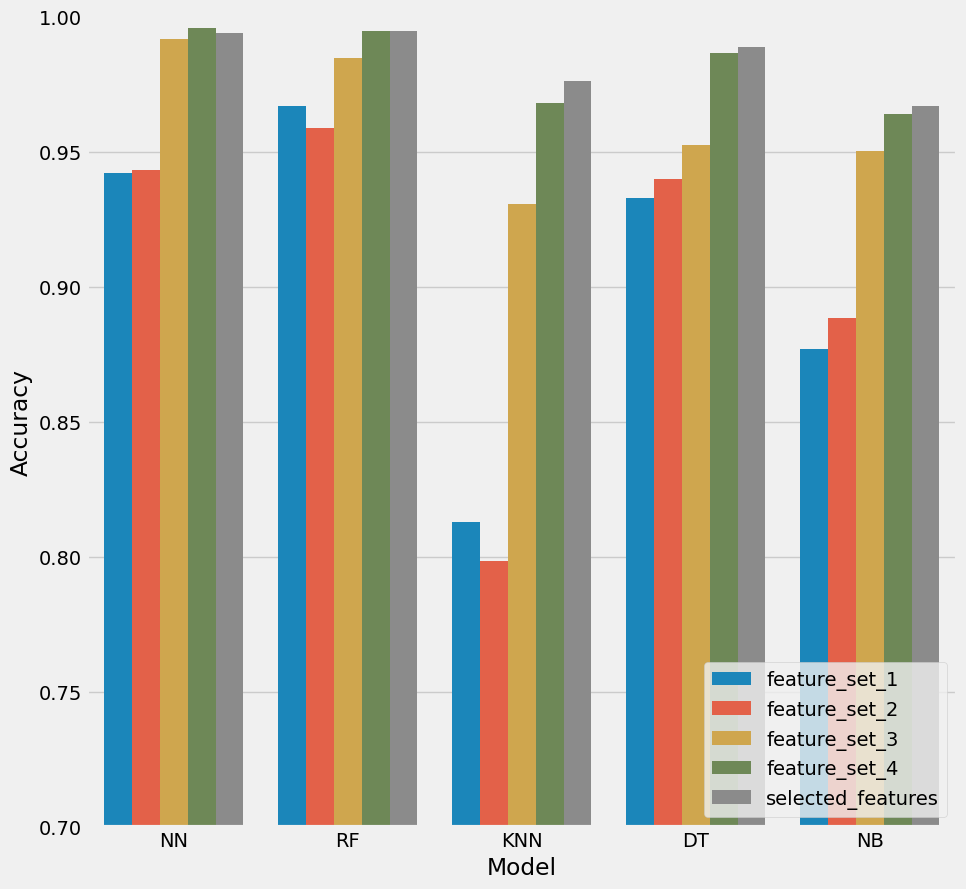

In [93]:
plt.figure(figsize=(10, 10))
sns.barplot(x="model", y="accuracy", hue="feature_set", data=score_df)
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0.7, 1)
plt.legend(loc="lower right")
plt.show()

In [96]:
#RF random forest model perform very well with the selected features.

In [97]:
(   class_train_y,
    class_test_y,
    class_train_prob_y,
    class_test_prob_y,
) = learner.random_forest(
    x_train[feature_set_4], y_train,x_test[feature_set_4], gridsearch=True
)

In [99]:
accuracy=accuracy_score(y_test, class_test_y)
accuracy

0.9948293691830403

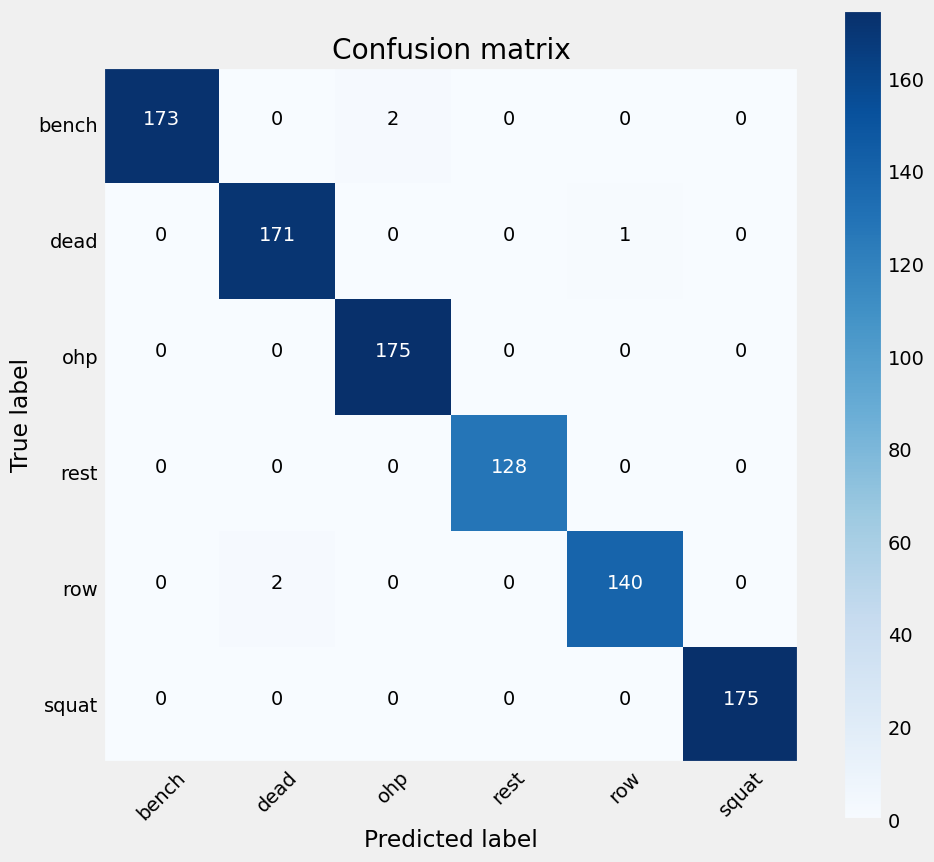

In [100]:
classes = class_test_prob_y.columns
cm = confusion_matrix(y_test, class_test_y, labels=classes)

# create confusion matrix for cm
plt.figure(figsize=(10, 10))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.colorbar()
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

thresh = cm.max() / 2.0
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(
        j,
        i,
        format(cm[i, j]),
        horizontalalignment="center",
        color="white" if cm[i, j] > thresh else "black",
    )
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.grid(False)
plt.show()

In [101]:
#select train and test data based on participant

In [102]:
participant_df=df.drop(["category","set"],axis=1)

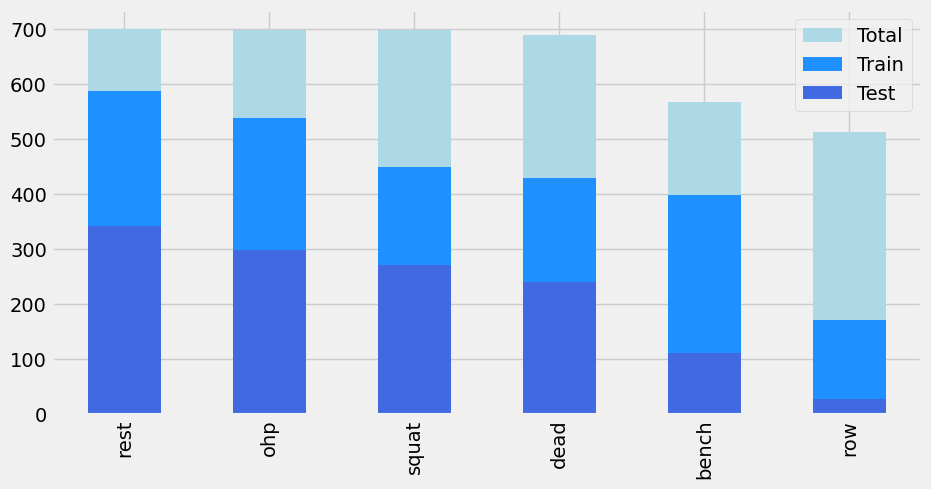

In [108]:
x_train=participant_df[participant_df["participant"]!="A"].drop(["label"],axis=1)
y_train=participant_df[participant_df["participant"]!="A"]["label"]

x_test=participant_df[participant_df["participant"]=="A"].drop(["label"],axis=1)
y_test=participant_df[participant_df["participant"]=="A"]["label"]

x_train=x_train.drop(["participant"],axis=1)
x_test=x_test.drop(["participant"],axis=1)

fig,ax = plt.subplots(figsize=(10, 5))
df_train["label"].value_counts().plot(kind="bar",ax=ax,color="lightblue",label="Total")
y_train.value_counts().plot(kind="bar",ax=ax,color="dodgerblue",label="Train")
y_test.value_counts().plot(kind="bar",ax=ax,color="royalblue",label="Test")
plt.legend()
plt.show()

In [109]:
#use best model again and evaluate results 

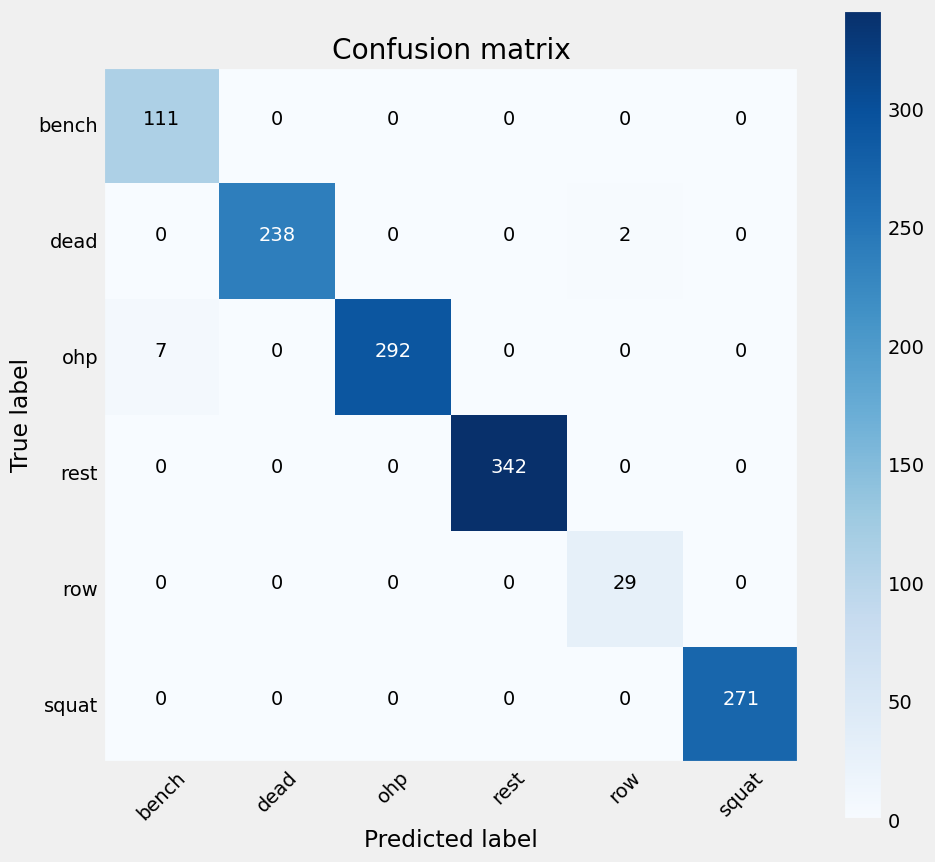

In [110]:
(   class_train_y,
    class_test_y,
    class_train_prob_y,
    class_test_prob_y,
) = learner.random_forest(
    x_train[feature_set_4], y_train,x_test[feature_set_4], gridsearch=True
)

accuracy=accuracy_score(y_test, class_test_y)
accuracy

classes = class_test_prob_y.columns
cm = confusion_matrix(y_test, class_test_y, labels=classes)

# create confusion matrix for cm
plt.figure(figsize=(10, 10))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.colorbar()
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

thresh = cm.max() / 2.0
for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(
        j,
        i,
        format(cm[i, j]),
        horizontalalignment="center",
        color="white" if cm[i, j] > thresh else "black",
    )
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.grid(False)
plt.show()


In [111]:
accuracy

0.9930340557275542